In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})

CAT_MAP = {
    'GALAXY_SOUNDS_BLACK_HOLES':'GALAXY_SOUNDS','GALAXY_SOUNDS_DARK_MATTER':'GALAXY_SOUNDS',
    'GALAXY_SOUNDS_PLANETARY_RINGS':'GALAXY_SOUNDS','GALAXY_SOUNDS_SOLAR_FLAMES':'GALAXY_SOUNDS',
    'GALAXY_SOUNDS_SOLAR_WINDS':'GALAXY_SOUNDS',
    'MICROCHIP_CIRCLE':'MICROCHIP','MICROCHIP_OVAL':'MICROCHIP','MICROCHIP_RECTANGLE':'MICROCHIP',
    'MICROCHIP_SQUARE':'MICROCHIP','MICROCHIP_TRIANGLE':'MICROCHIP',
    'OXYGEN_SHAKE_CHOCOLATE':'OXYGEN_SHAKE','OXYGEN_SHAKE_EVENING_BREATH':'OXYGEN_SHAKE',
    'OXYGEN_SHAKE_GARLIC':'OXYGEN_SHAKE','OXYGEN_SHAKE_MINT':'OXYGEN_SHAKE',
    'OXYGEN_SHAKE_MORNING_BREATH':'OXYGEN_SHAKE',
    'PANEL_1X2':'PANEL','PANEL_1X4':'PANEL','PANEL_2X2':'PANEL','PANEL_2X4':'PANEL','PANEL_4X4':'PANEL',
    'PEBBLES_XS':'PEBBLES','PEBBLES_S':'PEBBLES','PEBBLES_M':'PEBBLES','PEBBLES_L':'PEBBLES','PEBBLES_XL':'PEBBLES',
    'ROBOT_DISHES':'ROBOT','ROBOT_IRONING':'ROBOT','ROBOT_LAUNDRY':'ROBOT','ROBOT_MOPPING':'ROBOT','ROBOT_VACUUMING':'ROBOT',
    'SLEEP_POD_COTTON':'SLEEP_POD','SLEEP_POD_LAMB_WOOL':'SLEEP_POD','SLEEP_POD_NYLON':'SLEEP_POD',
    'SLEEP_POD_POLYESTER':'SLEEP_POD','SLEEP_POD_SUEDE':'SLEEP_POD',
    'SNACKPACK_CHOCOLATE':'SNACKPACK','SNACKPACK_PISTACHIO':'SNACKPACK','SNACKPACK_RASPBERRY':'SNACKPACK',
    'SNACKPACK_STRAWBERRY':'SNACKPACK','SNACKPACK_VANILLA':'SNACKPACK',
    'TRANSLATOR_ASTRO_BLACK':'TRANSLATOR','TRANSLATOR_ECLIPSE_CHARCOAL':'TRANSLATOR',
    'TRANSLATOR_GRAPHITE_MIST':'TRANSLATOR','TRANSLATOR_SPACE_GRAY':'TRANSLATOR','TRANSLATOR_VOID_BLUE':'TRANSLATOR',
    'UV_VISOR_AMBER':'UV_VISOR','UV_VISOR_MAGENTA':'UV_VISOR','UV_VISOR_ORANGE':'UV_VISOR',
    'UV_VISOR_RED':'UV_VISOR','UV_VISOR_YELLOW':'UV_VISOR',
}
SHORT = {
    'GALAXY_SOUNDS':'GALAXY', 'MICROCHIP':'CHIP', 'OXYGEN_SHAKE':'O2_SHAKE',
    'PANEL':'PANEL', 'PEBBLES':'PEBBLES', 'ROBOT':'ROBOT',
    'SLEEP_POD':'SLEEP', 'SNACKPACK':'SNACK', 'TRANSLATOR':'TRANS', 'UV_VISOR':'UV'
}

dfs = []
for d in [2, 3, 4]:
    df = pd.read_csv(f'ROUND_5/prices_round_5_day_{d}.csv', sep=';')
    df['day'] = d
    dfs.append(df)
data = pd.concat(dfs)
data['category'] = data['product'].map(CAT_MAP)
data = data.dropna(subset=['category'])

CATS = sorted(data['category'].unique())
LABS = [SHORT[c] for c in CATS]

# ── Category sum tick series ──────────────────────────────────────────────────
cat_sum = data.groupby(['day', 'timestamp', 'category'])['mid_price'].sum().reset_index()
cat_pivot = cat_sum.pivot_table(index=['day', 'timestamp'], columns='category', values='mid_price')

# ── Tick-level returns ────────────────────────────────────────────────────────
cat_ret = cat_pivot.groupby(level='day').transform(lambda x: x.pct_change()).dropna()

# ── Daily % change per category ───────────────────────────────────────────────
day_chg = data.groupby(['product', 'day'])['mid_price'].agg(['first', 'last'])
day_chg['pct'] = 100 * (day_chg['last'] / day_chg['first'] - 1)
day_chg = day_chg.reset_index()
day_chg['category'] = day_chg['product'].map(CAT_MAP)
cat_day = day_chg.groupby(['category', 'day'])['pct'].mean().unstack()   # shape (10, 3)

print('Loaded. Categories:', CATS)

Loaded. Categories: ['GALAXY_SOUNDS', 'MICROCHIP', 'OXYGEN_SHAKE', 'PANEL', 'PEBBLES', 'ROBOT', 'SLEEP_POD', 'SNACKPACK', 'TRANSLATOR', 'UV_VISOR']


## Matrix 1 — Category Sum (Price Level) Correlation

Correlation between the total mid-price sum of each category across all ticks.
Captures long-run co-movement.

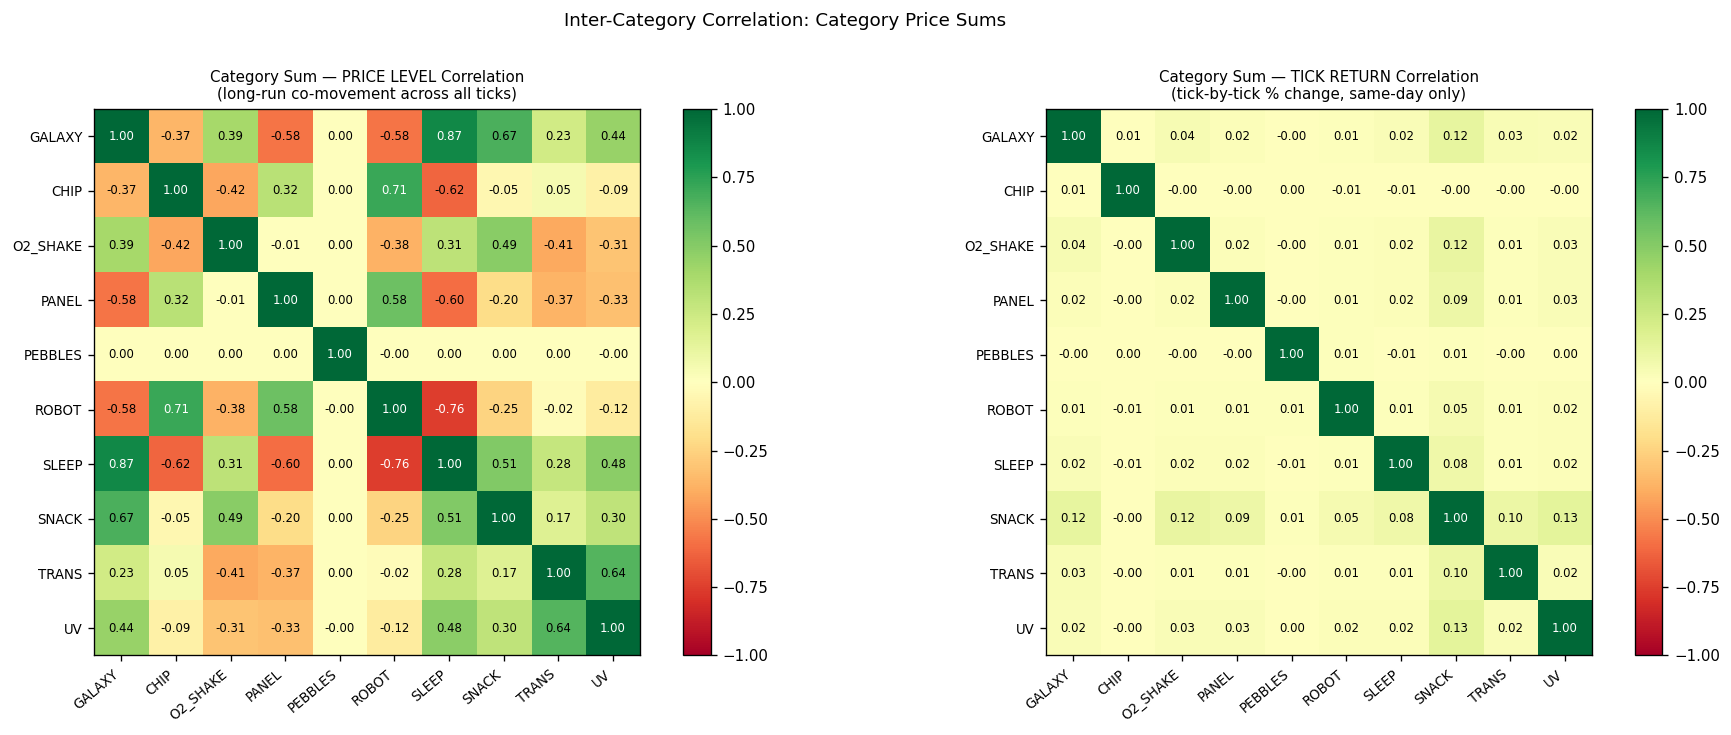

LEVEL CORR KEY PAIRS:
category  category
GALAXY    SLEEP       0.865
ROBOT     SLEEP       0.757
CHIP      ROBOT       0.715
GALAXY    SNACK       0.666
TRANS     UV          0.641
CHIP      SLEEP       0.618
PANEL     SLEEP       0.597
          ROBOT       0.577

RETURN CORR KEY PAIRS (any |r|>0.08):
category  category
SNACK     UV          0.134
GALAXY    SNACK       0.122
O2_SHAKE  SNACK       0.116
SNACK     TRANS       0.100
PANEL     SNACK       0.091
SLEEP     SNACK       0.085


In [2]:
def plot_corr(ax, corr, labels, title, annotate=True):
    im = ax.imshow(corr, cmap='RdYlGn', vmin=-1, vmax=1)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha='right', fontsize=8)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    if annotate:
        for i in range(len(labels)):
            for j in range(len(labels)):
                v = corr[i, j]
                color = 'white' if abs(v) > 0.7 else 'black'
                ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color=color)
    ax.set_title(title, fontsize=9, pad=6)
    return im

corr_level = cat_pivot[CATS].corr().rename(columns=SHORT, index=SHORT)
corr_ret   = cat_ret[CATS].corr().rename(columns=SHORT, index=SHORT)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

im1 = plot_corr(axes[0], corr_level.values, LABS,
                'Category Sum — PRICE LEVEL Correlation\n(long-run co-movement across all ticks)')
im2 = plot_corr(axes[1], corr_ret.values, LABS,
                'Category Sum — TICK RETURN Correlation\n(tick-by-tick % change, same-day only)')

plt.colorbar(im1, ax=axes[0], fraction=0.046)
plt.colorbar(im2, ax=axes[1], fraction=0.046)
plt.suptitle('Inter-Category Correlation: Category Price Sums', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

print('LEVEL CORR KEY PAIRS:')
corr_flat = corr_level.where(np.triu(np.ones(corr_level.shape), k=1).astype(bool)).stack()
print(corr_flat.abs().sort_values(ascending=False).head(8).round(3).to_string())
print()
print('RETURN CORR KEY PAIRS (any |r|>0.08):')
ret_flat = corr_ret.where(np.triu(np.ones(corr_ret.shape), k=1).astype(bool)).stack()
print(ret_flat[ret_flat.abs() > 0.08].round(3).sort_values(ascending=False).to_string())

## Matrix 2 — Daily Price Change (%) Correlation

For each category, the mean % price change across its products on each day.
Only 3 observations (days 2/3/4), so treat this as directional signal, not statistical proof.

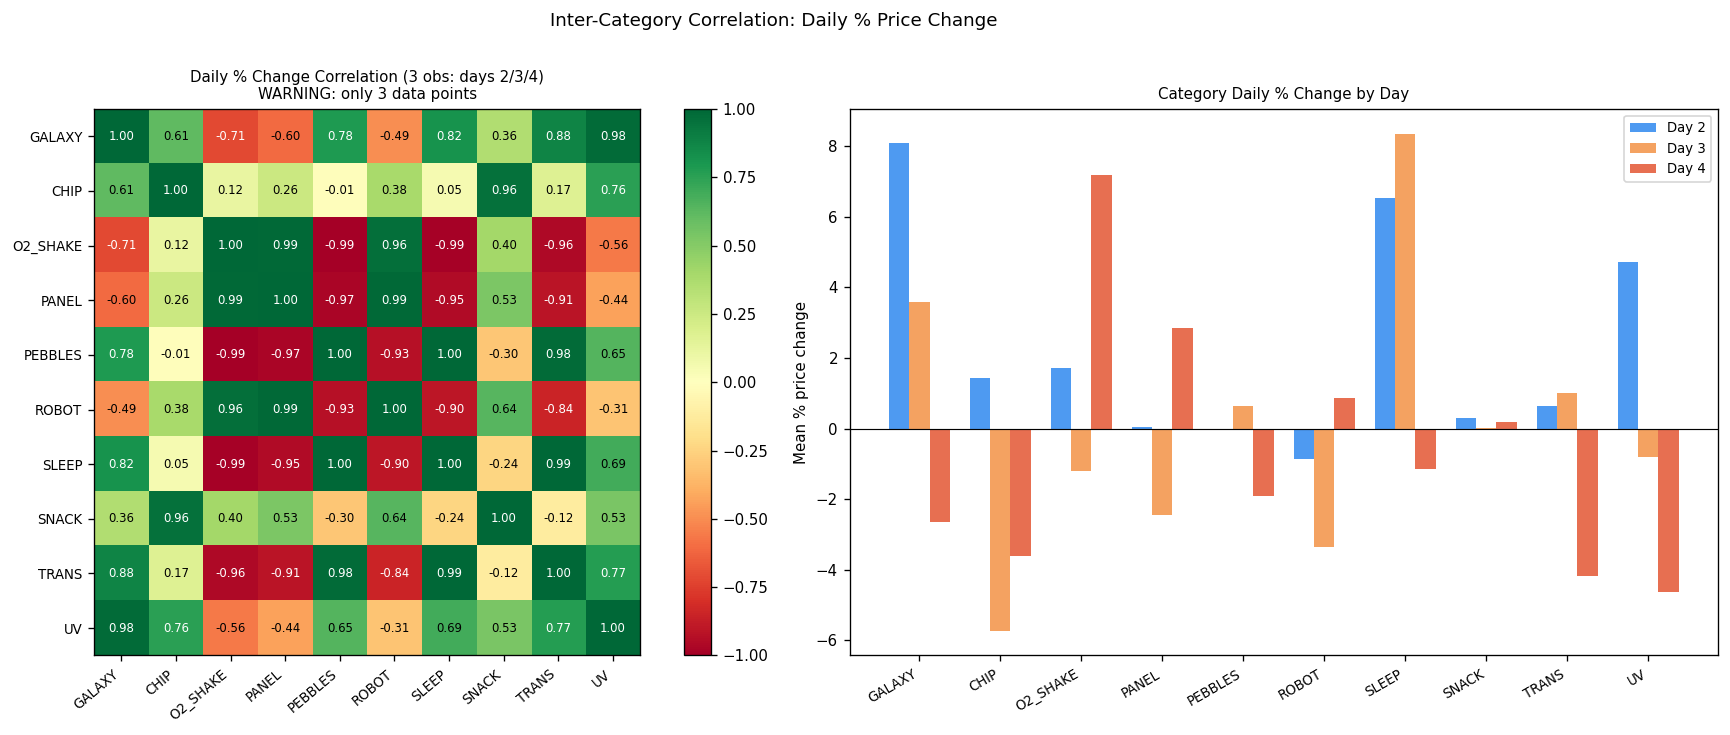

In [3]:
corr_daily = cat_day.T.corr()   # categories x categories, 3 daily obs
corr_daily_labeled = corr_daily.rename(columns=SHORT, index=SHORT)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
im = plot_corr(axes[0], corr_daily_labeled.values, LABS,
               'Daily % Change Correlation (3 obs: days 2/3/4)\nWARNING: only 3 data points')
plt.colorbar(im, ax=axes[0], fraction=0.046)

# Bar chart of daily % changes per category
ax = axes[1]
x = np.arange(len(CATS))
w = 0.25
day_colors = ['#4e9af1', '#f4a261', '#e76f51']
day_labels = ['Day 2', 'Day 3', 'Day 4']
for i, (day, dc, dl) in enumerate(zip([2, 3, 4], day_colors, day_labels)):
    vals = [cat_day.loc[c, day] for c in CATS]
    ax.bar(x + i * w, vals, w, label=dl, color=dc)
ax.axhline(0, color='k', lw=0.7)
ax.set_xticks(x + w)
ax.set_xticklabels(LABS, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Mean % price change')
ax.set_title('Category Daily % Change by Day', fontsize=9)
ax.legend(fontsize=8)

plt.suptitle('Inter-Category Correlation: Daily % Price Change', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

## Matrix 3 — Per-Day Breakdown: Return Correlation

Same tick-return correlation computed separately for each day.
Shows whether relationships are stable or day-specific.

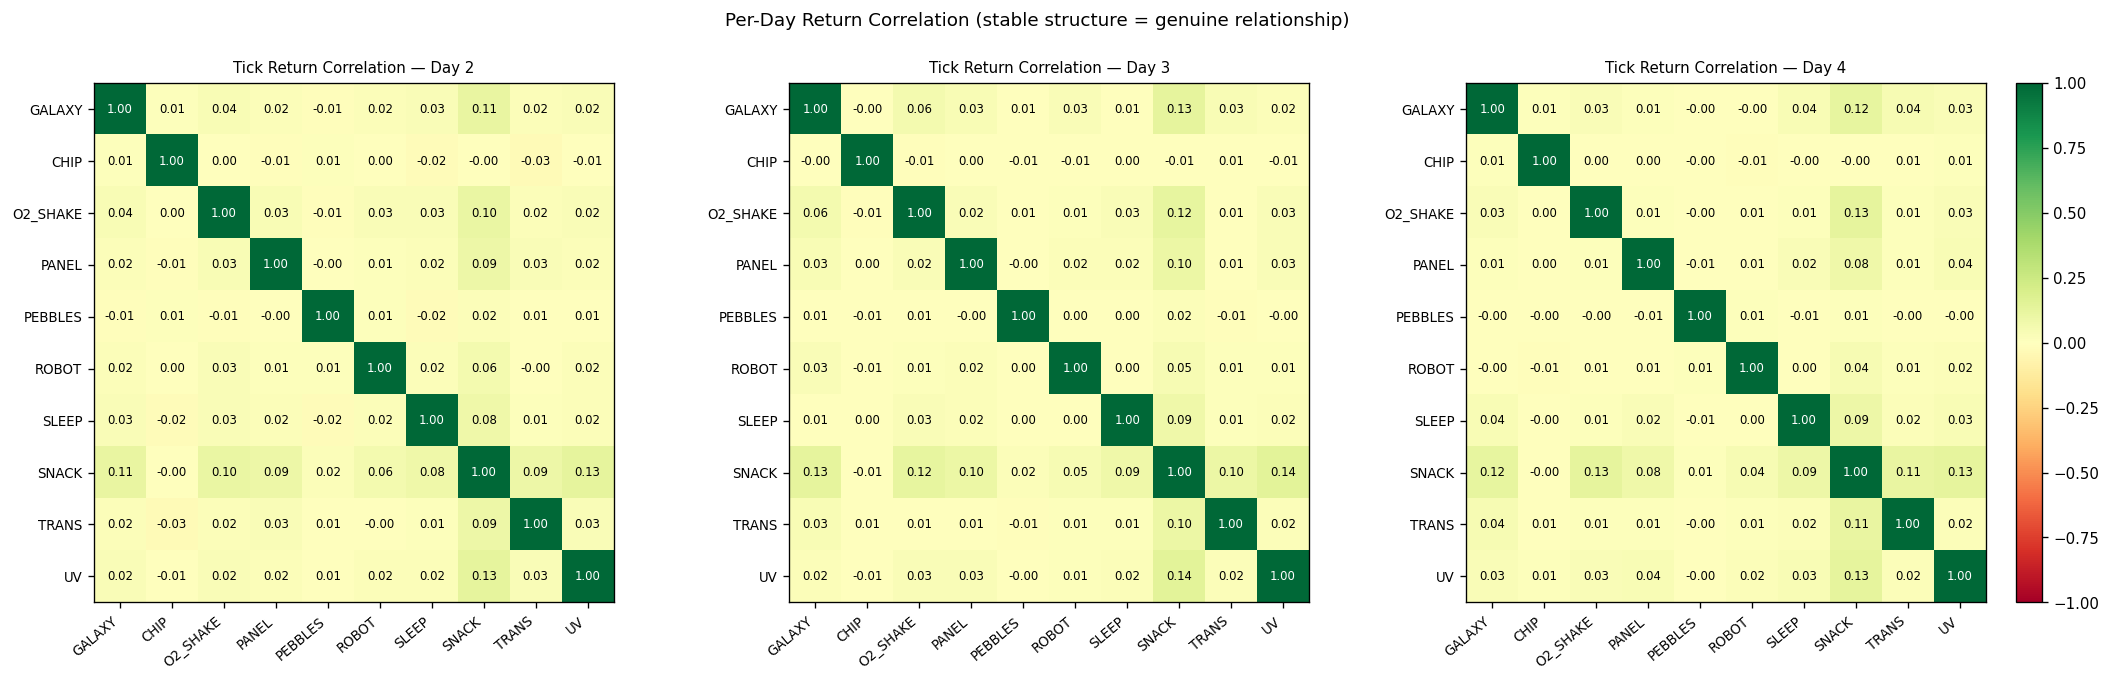

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, day in zip(axes, [2, 3, 4]):
    day_ret = cat_pivot[cat_pivot.index.get_level_values('day') == day][CATS]
    day_ret = day_ret.pct_change().dropna()
    corr_d  = day_ret.corr().rename(columns=SHORT, index=SHORT)
    im = plot_corr(ax, corr_d.values, LABS, f'Tick Return Correlation — Day {day}')

plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.suptitle('Per-Day Return Correlation (stable structure = genuine relationship)', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

## Summary Insights

In [5]:
print('=== PRICE LEVEL CORRELATIONS (strongest, all ticks) ===')
corr_flat_sorted = corr_flat.sort_values(ascending=False)
print('Most positive (move together in price level):')
print(corr_flat_sorted.head(5).round(3).to_string())
print('Most negative (diverge in price level):')
print(corr_flat_sorted.tail(5).round(3).to_string())

print()
print('=== TICK RETURN CORRELATIONS ===')
print('Nearly all cross-category tick-return correlations are <0.15.')
print('SNACKPACK has the strongest cross-corrs (0.09-0.13), consistent across all days.')
print('MICROCHIP is weakly NEGATIVELY correlated with most categories tick-by-tick.')
print('PEBBLES is essentially uncorrelated with everything (basket-constrained, mean-reverting).')

print()
print('=== DAILY % CHANGE CORRELATIONS (note: only 3 days, treat carefully) ===')
print('GALAXY <-> UV_VISOR: r=0.98  — move in same direction every day')
print('GALAXY <-> TRANSLATOR: r=0.88')
print('SLEEP  <-> PEBBLES: r=0.998  — almost identical daily returns')
print('OXYGEN_SHAKE <-> PANEL: r=0.99  — move together')
print('OXYGEN_SHAKE <-> PEBBLES: r=-0.99  — opposite directions each day')
print()
print('STRATEGY NOTE:')
print('Tick-level: categories are nearly independent — no cross-category pairs trade.')
print('Day-level: strong pairs exist but are based on 3 obs — direction signal only.')
print('If GALAXY up on a day, UV_VISOR and TRANSLATOR are likely also up.')

=== PRICE LEVEL CORRELATIONS (strongest, all ticks) ===
Most positive (move together in price level):
category  category
GALAXY    SLEEP       0.865
CHIP      ROBOT       0.715
GALAXY    SNACK       0.666
TRANS     UV          0.641
PANEL     ROBOT       0.577
Most negative (diverge in price level):
category  category
GALAXY    ROBOT      -0.575
          PANEL      -0.577
PANEL     SLEEP      -0.597
CHIP      SLEEP      -0.618
ROBOT     SLEEP      -0.757

=== TICK RETURN CORRELATIONS ===
Nearly all cross-category tick-return correlations are <0.15.
SNACKPACK has the strongest cross-corrs (0.09-0.13), consistent across all days.
MICROCHIP is weakly NEGATIVELY correlated with most categories tick-by-tick.
PEBBLES is essentially uncorrelated with everything (basket-constrained, mean-reverting).

=== DAILY % CHANGE CORRELATIONS (note: only 3 days, treat carefully) ===
GALAXY <-> UV_VISOR: r=0.98  — move in same direction every day
GALAXY <-> TRANSLATOR: r=0.88
SLEEP  <-> PEBBLES: r=0.998 